<a href="https://colab.research.google.com/github/fakhreeva2005-tech/AI-Image-Description/blob/main/AI_Image_Description_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✨ AI Image Description

### Демонстрация предобученных моделей машинного обучения в Google Colab

**Цель проекта:** разработка веб-приложения для автоматического анализа изображений и генерации текстовых описаний на английском и русском языках.

**Используемые модели:**
- **BLIP (Salesforce/blip-image-captioning-base)** — распознавание содержимого изображения и генерация текстового описания.
- **OPUS-MT (Helsinki-NLP/opus-mt-en-ru)** — автоматический перевод описания с английского языка на русский.
- **Florence-2 (florence-community/Florence-2-base-ft)** — подробное описание изображений (реализовано в веб-приложении).

**Технологии:** Python, PyTorch, Hugging Face Transformers, Google Colab, Streamlit.

**Результат:** автоматическое формирование описания загруженного изображения на двух языках.

**GitHub:** https://github.com/fakhreeva2005-tech/AI-Image-Description

**Веб-приложение:** https://ai-image-description-elvira.streamlit.app

In [1]:
!pip install -q transformers accelerate pillow sentencepiece

In [2]:
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration

model_name = "Salesforce/blip-image-captioning-base"

print("Загружаем модель BLIP...")

processor = BlipProcessor.from_pretrained(model_name)
model = BlipForConditionalGeneration.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

print("Модель BLIP успешно загружена!")
print("Устройство:", device)

Загружаем модель BLIP...


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Модель BLIP успешно загружена!
Устройство: cpu


Saving кот.png to кот.png


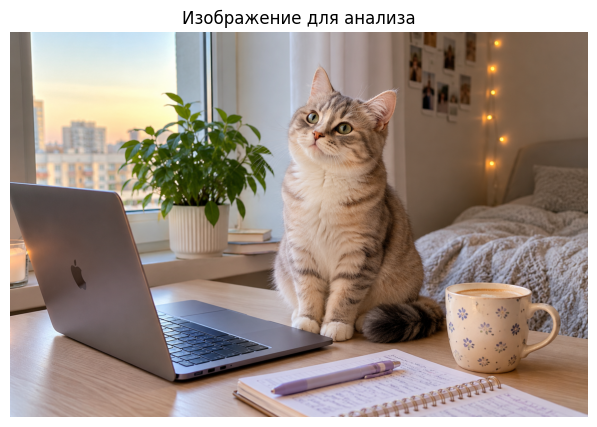

Изображение успешно загружено!


In [3]:
from google.colab import files
from PIL import Image
import io
import matplotlib.pyplot as plt

# Загружаем изображение с компьютера
uploaded = files.upload()

# Открываем загруженную фотографию
filename = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

# Показываем фотографию
plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Изображение для анализа")
plt.show()

print("Изображение успешно загружено!")

In [4]:
# Подготавливаем изображение для нейросети
inputs = processor(
    images=image,
    return_tensors="pt"
).to(device)

# Генерируем описание изображения
with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=50
    )

# Преобразуем результат в текст
caption = processor.decode(
    output[0],
    skip_special_tokens=True
)

print("Описание изображения:")
print(caption)

Описание изображения:
a cat sitting on a table next to a laptop


In [5]:
from transformers import MarianMTModel, MarianTokenizer

translation_model_name = "Helsinki-NLP/opus-mt-en-ru"

print("Загружаем модель перевода OPUS-MT...")

tokenizer_ru = MarianTokenizer.from_pretrained(
    translation_model_name
)

model_ru = MarianMTModel.from_pretrained(
    translation_model_name
)

model_ru.eval()

print("Модель перевода успешно загружена!")

Загружаем модель перевода OPUS-MT...


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/803k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  307MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Модель перевода успешно загружена!


In [6]:
# Подготавливаем английское описание для перевода
translation_inputs = tokenizer_ru(
    caption,
    return_tensors="pt",
    padding=True,
    truncation=True
)

# Генерируем перевод на русский язык
with torch.no_grad():
    translated_tokens = model_ru.generate(
        **translation_inputs,
        max_new_tokens=100
    )

# Преобразуем результат в текст
russian_caption = tokenizer_ru.decode(
    translated_tokens[0],
    skip_special_tokens=True
)

# Выводим результаты
print("🇬🇧 Описание на английском:")
print(caption)

print("\n🇷🇺 Описание на русском:")
print(russian_caption)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


🇬🇧 Описание на английском:
a cat sitting on a table next to a laptop

🇷🇺 Описание на русском:
Кот, сидящий на столе рядом с ноутбуком
